# Exploratory Data Analysis

This notebook explores the selected GSE131907 raw count data. Run the notebook from the repository root.

In [1]:
import os

# Allow execution from either the repository root or notebooks directory.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import seaborn as sns
import yaml
from anndata import AnnData
from IPython.display import display
from scipy.io import mmread

FIGURE_DIR = "outputs/figures"

# Store notebook figures with the other generated project outputs.
os.makedirs(FIGURE_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

## Data overview

The Matrix Market file stores genes by cells. The transpose below creates the cells-by-genes orientation required by `AnnData`. The summary reports the matrix size, sparsity, and raw cell-level metrics for each sample.

In [2]:
with open("configs/default.yml") as file:
    config = yaml.safe_load(file)

sample_order = config["dataset"]["selected_samples"]
counts = mmread("data/processed/lung_tumor_raw_counts.mtx").T.tocsr()
cells = pd.read_csv("data/processed/lung_tumor_cells.tsv", sep="\t")
genes = pd.read_csv(
    "data/processed/lung_tumor_genes.tsv",
    header=None,
    names=["gene"]
)

# Build a sparse cells by genes object and retain sample membership.
adata = AnnData(
    X=counts,
    obs=cells.set_index("cell_id"),
    var=pd.DataFrame(index=genes["gene"])
)
adata.obs["sample"] = pd.Categorical(
    adata.obs["sample"],
    categories=sample_order,
    ordered=True
)
# Identify mitochondrial genes from their standard gene-symbol prefix.
adata.var["mt"] = adata.var_names.str.startswith("MT-")

# Calculate count, detected-gene, and mitochondrial summaries for each cell.
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

dataset_summary = pd.DataFrame({
    "cells": [adata.n_obs],
    "genes": [adata.n_vars],
    "nonzero_entries": [adata.X.nnz],
    "matrix_density_percent": [100 * adata.X.nnz / (adata.n_obs * adata.n_vars)],
    "mitochondrial_genes": [adata.var["mt"].sum()]
}).round(2)

sample_summary = (
    adata.obs.groupby("sample", observed=False)
    .agg(
        cells=("sample", "size"),
        median_total_counts=("total_counts", "median"),
        median_detected_genes=("n_genes_by_counts", "median"),
        median_pct_counts_mt=("pct_counts_mt", "median")
    )
    .round(2)
)

display(adata)
display(dataset_summary)
display(sample_summary)

AnnData object with n_obs × n_vars = 45149 × 29634
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

,cells,genes,nonzero_entries,matrix_density_percent,mitochondrial_genes
0,45149,29634,71181726,5.32,13


,cells,median_total_counts,median_detected_genes,median_pct_counts_mt
sample,,,,
LUNG_T06,3426,3837.5,1194.5,3.72
LUNG_T08,3765,3479.0,1082.0,3.60
LUNG_T09,3840,3807.5,1197.0,3.71
LUNG_T18,3705,4096.0,1386.0,3.71
LUNG_T19,4361,4053.0,1198.0,3.47
LUNG_T20,4021,2966.0,1073.0,3.86
LUNG_T25,4374,3016.0,927.0,3.36
LUNG_T28,4705,3258.0,1126.0,4.27
LUNG_T30,4094,2697.0,1026.0,0.51


The selected dataset contains 45,149 cells and 29,634 genes in a sparse count matrix. Sample identifiers remain attached to every cell for all later analyses.

## Sample-level distributions

The panels below compare sample size and the raw distributions of total UMI counts, detected genes, and mitochondrial counts. Log scales are used for the two count metrics because they span a wide range.

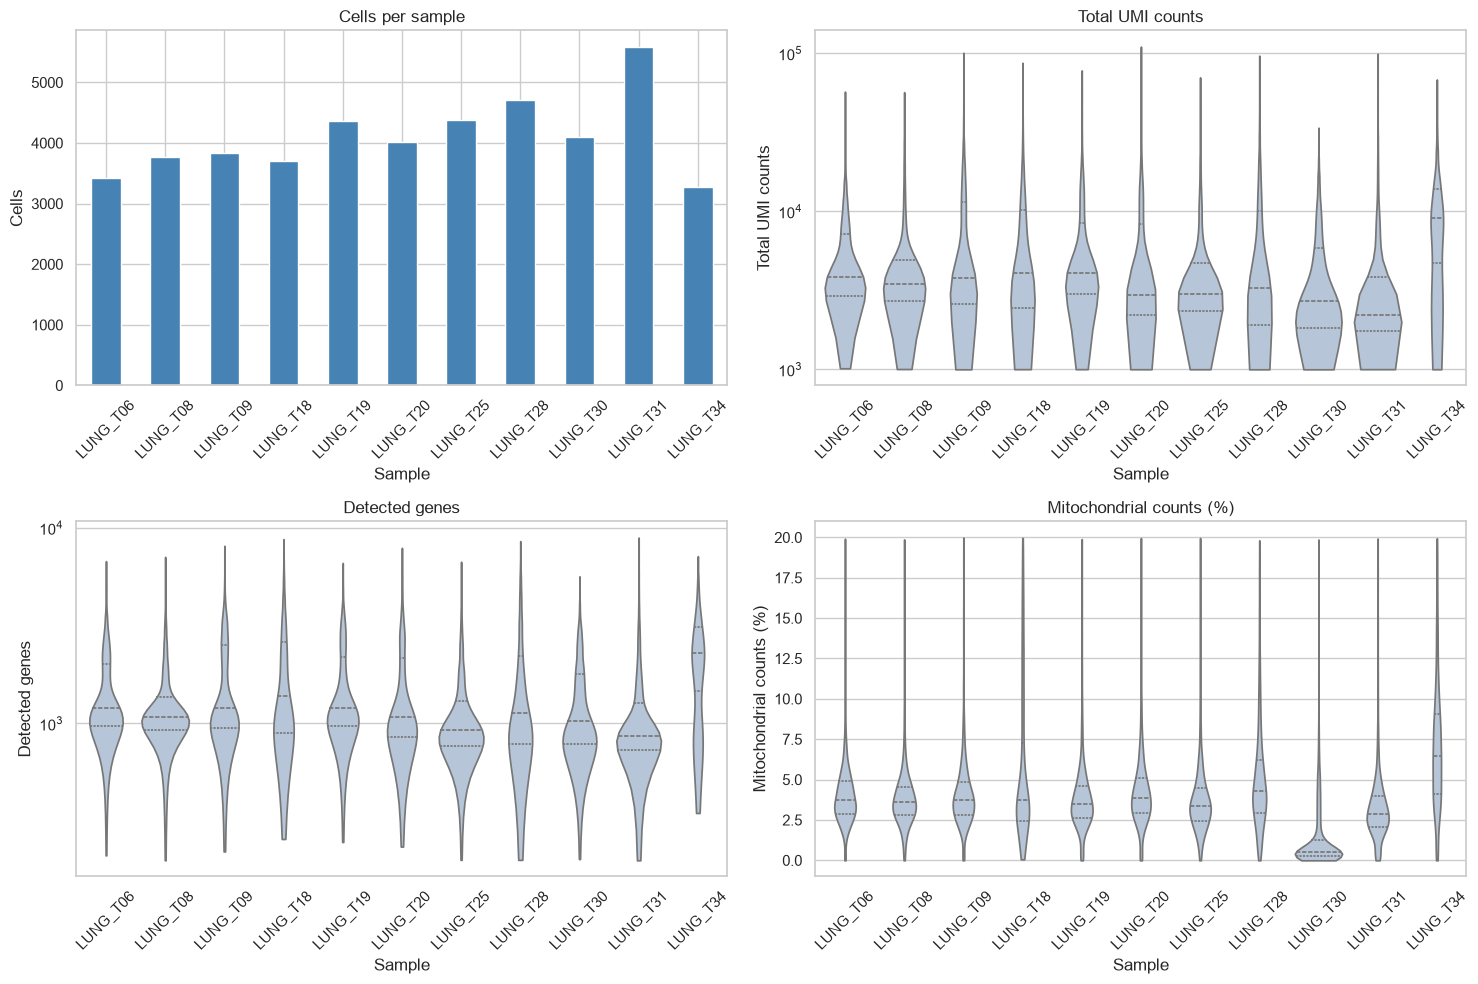

In [3]:
# Compare sample sizes and cell-level metric distributions before filtering.
sample_counts = adata.obs["sample"].value_counts().reindex(sample_order)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sample_counts.plot.bar(ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Cells per sample")
axes[0, 0].set_xlabel("Sample")
axes[0, 0].set_ylabel("Cells")
axes[0, 0].tick_params(axis="x", rotation=45)

metrics = [
    ("total_counts", "Total UMI counts", True),
    ("n_genes_by_counts", "Detected genes", True),
    ("pct_counts_mt", "Mitochondrial counts (%)", False)
]

for axis, (metric, label, log_scale) in zip(axes.flat[1:], metrics):
    sns.violinplot(
        data=adata.obs,
        x="sample",
        y=metric,
        order=sample_order,
        cut=0,
        inner="quartile",
        color="lightsteelblue",
        ax=axis
    )
    axis.set_title(label)
    axis.set_xlabel("Sample")
    axis.set_ylabel(label)
    axis.tick_params(axis="x", rotation=45)
    if log_scale:
        axis.set_yscale("log")

fig.tight_layout()
fig.savefig(
    os.path.join(FIGURE_DIR, "eda_sample-and-metric-overview.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

The samples differ in both size and raw expression distributions. `LUNG_T34` has higher total UMI counts, detected genes, and mitochondrial percentages, while `LUNG_T30` has lower mitochondrial percentages.

## Gene-level summary

The plots below show how widely each gene is detected and which genes contribute the most raw UMI counts across the selected cells.

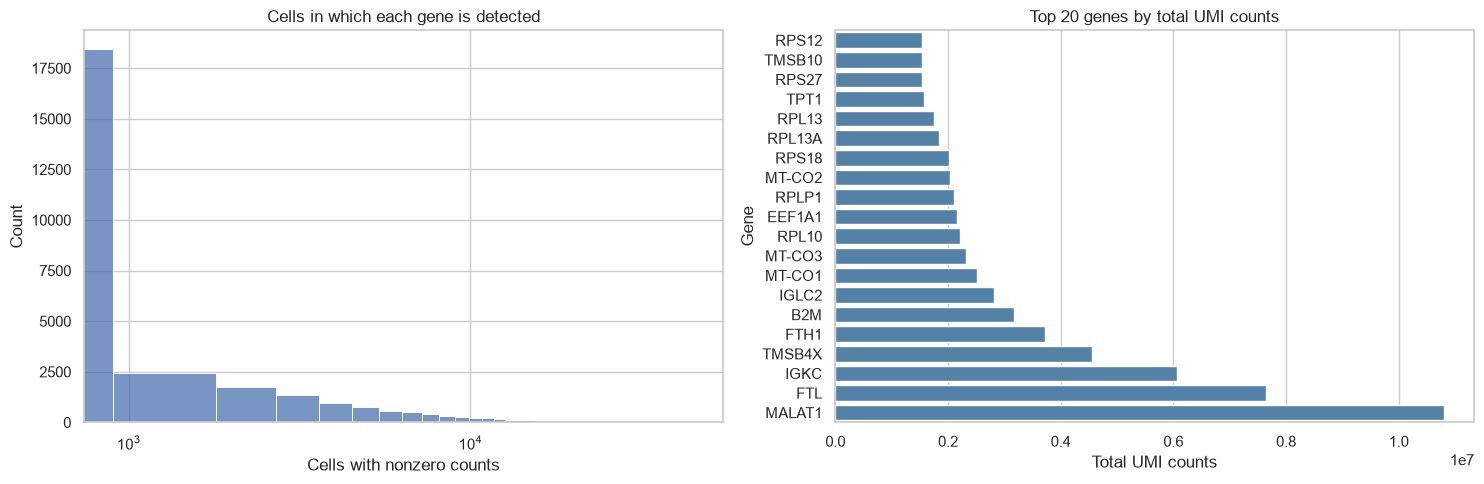

,total_counts,n_cells_by_counts
gene,,
MALAT1,10795827,44645
FTL,7636002,44848
IGKC,6055473,30944
TMSB4X,4561034,45094
FTH1,3725611,44963
B2M,3174575,45087
IGLC2,2823999,19507
MT-CO1,2514071,43393
MT-CO3,2311386,43732


In [4]:
# Summarize gene detection frequency and overall UMI abundance.
gene_metrics = adata.var[["total_counts", "n_cells_by_counts"]].copy()
top_genes = (
    gene_metrics.sort_values("total_counts", ascending=False)
    .head(20)
    .sort_values("total_counts")
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(gene_metrics["n_cells_by_counts"], bins=50, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_title("Cells in which each gene is detected")
axes[0].set_xlabel("Cells with nonzero counts")

sns.barplot(
    data=top_genes,
    x="total_counts",
    y=top_genes.index,
    color="steelblue",
    ax=axes[1]
)
axes[1].set_title("Top 20 genes by total UMI counts")
axes[1].set_xlabel("Total UMI counts")
axes[1].set_ylabel("Gene")

fig.tight_layout()
fig.savefig(
    os.path.join(FIGURE_DIR, "eda_gene-summary.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

top_genes.sort_values("total_counts", ascending=False)

Gene detection follows a long-tailed pattern. A small set of genes is detected in many cells, while many genes are observed less often. The top-count genes describe raw expression composition only.